In [8]:
from astropy import units as u
from streamsculptor.main import usys
import jax.numpy as jnp
from astropy.coordinates import SkyCoord, Galactocentric

import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)

from streamsculptor import potential
from streamsculptor import JaxCoords as jc #provides cartesian to ICRS coordinte conversion
from streamsculptor import usys
from streamsculptor import gen_stream_Chen25 #provide the Chen25 stream generation function


import diffrax #supplies the ODE solvers used to integrate orbits and generate streams
import matplotlib as mpl
import streamsculptor as ssc #provide the Chen25 stream generation function (used for unperturbed stream), 

from astropy.table import Table #reads the Gaia member data from an ECSV table
import numpy as np
import interpax  #interpolates the modelled stream'sphase-space coordinates
import equinox as eqx  #provides jax compatible utilities including jit
import tqdm #displays progress bars for longer loops

In [9]:
@jax.jit
def icrs_to_gd1(ra_rad, dec_rad):
    """
    Differentiable ra, dec --> gd1 phi1, phi2 (Koposov+2010 rotation matrix). 
    ra_rad, dec_rad in radians.
    """
    """
    Koposov+2010 rotation matrix converts from 3D ICRS to the GD-1 coordinates frame
    """
    
    R = jnp.array(
        [
            [-0.4776303088, -0.1738432154, 0.8611897727],
            [0.510844589, -0.8524449229, 0.111245042],
            [0.7147776536, 0.4930681392, 0.4959603976],
        ]
    )
                                                              #converts each (ra,dec) pair into a unit cartesian direction vector
    icrs_vec = jnp.vstack([jnp.cos(ra_rad)*jnp.cos(dec_rad),  #x-component
                           jnp.sin(ra_rad)*jnp.cos(dec_rad),  #y-component
                           jnp.sin(dec_rad)]).T               #z-component
                                                              #this gives a tabls with one row per star(N) and three columns (x,y,z). So, (N,3).

    stream_frame_vec = jnp.einsum('ij,kj->ki', R, icrs_vec)   #appies R to every vector, producing coordinates in the GD-1 oriented frame 
                                                              #einsum= Einstien Summation
    
    phi1 = jnp.arctan2(stream_frame_vec[:,1], stream_frame_vec[:,0])*180/jnp.pi #calculates the stream phase longitude with acrtan(y,x) and converts radians to degrees
    phi2 = jnp.arcsin(stream_frame_vec[:,2])*180/jnp.pi                         #calculates stream-frame lattitude with arcsin(z) and converts radians to degrees

    return phi1, phi2

@jax.jit
def get_phi12_from_stream(stream):
    """Differentiable helper: simulated stream --> phi1, phi2."""
    ra_s, dec_s, dist_ = jax.vmap(jc.simcart_to_icrs)(stream[:,:3])
    phi1_model, phi2_model = icrs_to_gd1(ra_s*jnp.pi/180, dec_s*jnp.pi/180)
    return phi1_model, phi2_model

In [10]:
prog_wtoday = jnp.array([-11.88431447,   1.61212652,   7.14988315,  -0.09253346, -0.22701121,  -0.10732978]) #location from GD1_progenitor.npy
#

In [11]:
def gen_stream(t_age, Msat, N_tail, t_dissolve, seed=532):
    IC = pot.integrate_orbit(w0=prog_wtoday, t0=0.0, t1=-t_age, ts=jnp.array([-t_age])).ys[0] #initial conditions
    ts = jnp.hstack([jnp.linspace(-t_age, t_dissolve, N_tail), jnp.array([0.0])])
    l, t = ssc.gen_stream_Chen25(pot_base=pot, ts=ts, prog_w0=IC, Msat=Msat,
                             key=jax.random.PRNGKey(532), method="vmap",           
                             solver=diffrax.Dopri8(), atol=1e-7, rtol=1e-7, dtmin=0.1)
    stream = jnp.vstack([l,t])
    phi1, phi2 = get_phi12_from_stream(stream)
    return np.array(phi1), np.asarray(phi2)

In [12]:
pot = potential.BovyMWPotential2014(units=usys)

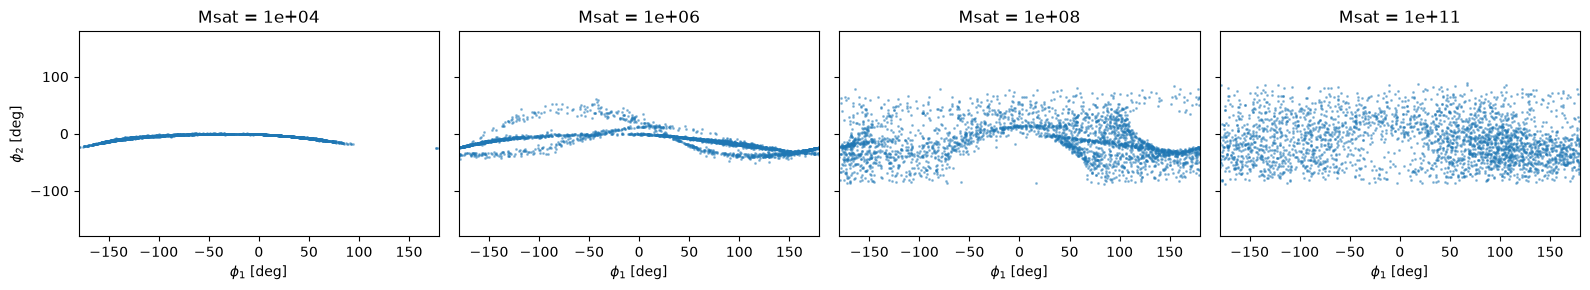

In [20]:
#Side by side
masses = [1e4, 1e6, 1e8, 1e11]
colours = ["tab:red", "tab:green", "tab:orange", "tab:blue"]

t_age = 20_000
t_dissolve = -300

N_tail = 1_500

fig, axes = plt.subplots(1, len(masses), figsize=(16, 3), sharex=True, sharey=True)
for ax, Msat in zip(axes, masses):
    phi1, phi2 = gen_stream(t_age, N_tail=N_tail, t_dissolve=t_dissolve, Msat=Msat)
    ax.scatter(phi1, phi2, s=1.2, alpha=0.4, rasterized=True)
    ax.set_title(f"Msat = {Msat:.0e}")
    ax.set_xlabel(r"$\phi_1$ [deg]")
axes[0].set_ylabel(r"$\phi_2$ [deg]")
#axes[0].set_xlim(-100, 20); axes[0].set_ylim(-10, 10)
axes[0].set_xlim(-180, 180); axes[0].set_ylim(-180, 180)
plt.tight_layout()
plt.show()
#

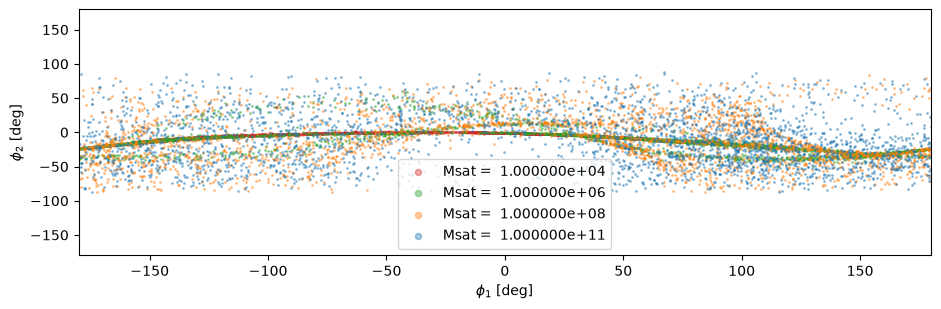

In [21]:
#Overlay
masses = [1e4, 1e6, 1e8, 1e11]
colours = ["tab:red", "tab:green", "tab:orange", "tab:blue"]

t_age = 20_000
t_dissolve = -300

N_tail = 1_500

fig, ax = plt.subplots(figsize=(11, 3.2))
for Msat, c in zip(masses, colours):
    phi1, phi2 = gen_stream(t_age, Msat=Msat, N_tail=N_tail, t_dissolve= t_dissolve)
    ax.scatter(phi1, phi2, s=1.2, color=c, alpha=0.4, label=f"Msat = {Msat: 0e}", rasterized=True)

ax.set_xlim(-180,180); ax.set_ylim(-180,180)
ax.set_xlabel(r"$\phi_1$ [deg]"); ax.set_ylabel(r"$\phi_2$ [deg]")
ax.legend(markerscale=4)
plt.show()